# UMAP Inspection by HPO Config

- **Purpose:** Generate inspection UMAPs for saved HPO runs.
- **Inputs:** Processed H5ADs; `models/hpo/` run configurations and latents.
- **Outputs:** Inspection plots shown in the notebook; no artifacts are saved.
- **Status:** Exploratory; visual inspection only, not part of model selection.


Plots UMAP panels of the combined latent for any finished HPO run, selected 
using `config_id` + `approach` (`joint` or `scarches`). 
The latent is not stored just recomputed on the fly from the saved model using the recorded models in `models/hpo/runs`

**Interpretation rules**: mixing is a necessary condition for
matching, not proof of a match; UMAP is a 2-D projection, never the decision
criterion.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.append(str(PROJECT_ROOT))

from src import model_io
from src.utils import load_config

print(f"Project root: {PROJECT_ROOT}")

Project root: /mnt/bigdisk/markus/CRC-scMFmap


## Data Loading, Function Definitions

In [2]:
def qc_metrics(adata):
    adata.var["mt"] = adata.var_names.str.startswith(("MT-"))
    adata.var["ribo"] = adata.var_names.str.startswith(("RPL", "RPS"))
    # adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")
    # adata.var["ig"] = adata.var_names.str.startswith(("IG"))
    # adata.var["hla"] = adata.var_names.str.startswith(("HLA"))
    # adata.var["hsp"] = adata.var_names.str.startswith(("HSP"))
    # adata.var["malat1"] = adata.var_names.str.startswith("MALAT1")
    # adata.var["xist"] = adata.var_names.str.startswith("XIST")

    sc.pp.calculate_qc_metrics(
        adata, qc_vars=["mt", "ribo"],
        percent_top=None,
        log1p=True, inplace=True
    )
    return adata

In [3]:
import json

cfg = load_config()
paths = cfg["paths"]
with open(PROJECT_ROOT / paths["hpo"]["configs"]) as f:
    CONFIG_NUM_HVG = {c["config_id"]: c["num_hvg"] for c in json.load(f)["configs"]}

_adata = {"tumor": None, "cl": None}


def load_run_adata_with_latent(config_id, approach):
    if _adata["tumor"] is None:
        _adata["tumor"] = ad.read_h5ad(PROJECT_ROOT / paths["processed"]["pp_tumor"])
        _adata["cl"] = ad.read_h5ad(PROJECT_ROOT / paths["processed"]["pp_cell_line"])

        _adata["tumor"] = qc_metrics(_adata["tumor"])
        _adata["cl"] = qc_metrics(_adata["cl"])

    run_dir = (
        PROJECT_ROOT / paths["hpo"]["runs"]
        / f"hvg{CONFIG_NUM_HVG[config_id]}"
        / f"config_{config_id:02d}"
        / approach
    )
    run = model_io.load_run_latent(run_dir, _adata["tumor"], _adata["cl"], approach)
    adata = run["combined"]
    adata.obsm["X_latent"] = run["latent"]
    return adata

In [4]:
def embed_umap(config_id, approach, seed=0):
    adata = load_run_adata_with_latent(config_id, approach)
    adata = adata[np.random.default_rng(0).permutation(adata.n_obs)].copy()

    sc.pp.neighbors(adata, use_rep="X_latent", random_state=seed)
    sc.tl.umap(adata, random_state=seed)
    return adata

In [5]:
def plot_umaps_sc(config_id, approach, seed=0):
    adata = embed_umap(config_id, approach, seed=seed)
    tag = (f"config {config_id} / {approach} / hvg{CONFIG_NUM_HVG[config_id]}")

    sc.pl.umap(
        adata,
        color=["batch"],
        title=f"{tag} - Batches",
    )

    sc.pl.umap(
        adata,
        color=["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"],
        show=False
    )
    plt.suptitle(f"{tag} - Metrics", fontsize=16, fontweight="bold", y=1.02, x=0.45)
    plt.show()

    sc.pl.umap(
        adata,
        mask_obs=(adata.obs.dataset=="tumor"),
        color=["label"],
        title=f"{tag} - Pelka labeled Tumor States",
        na_in_legend=False,
    )

    sc.pl.umap(
        adata,
        mask_obs=(adata.obs.dataset=="cell_line"),
        color=["cell_line"],
        na_in_legend=False,
        title=f"{tag} - Cell Lines",
        size=10,
        alpha=0.45,
    )
    return adata

## UMAP best Models according to Fixed `K=100`

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


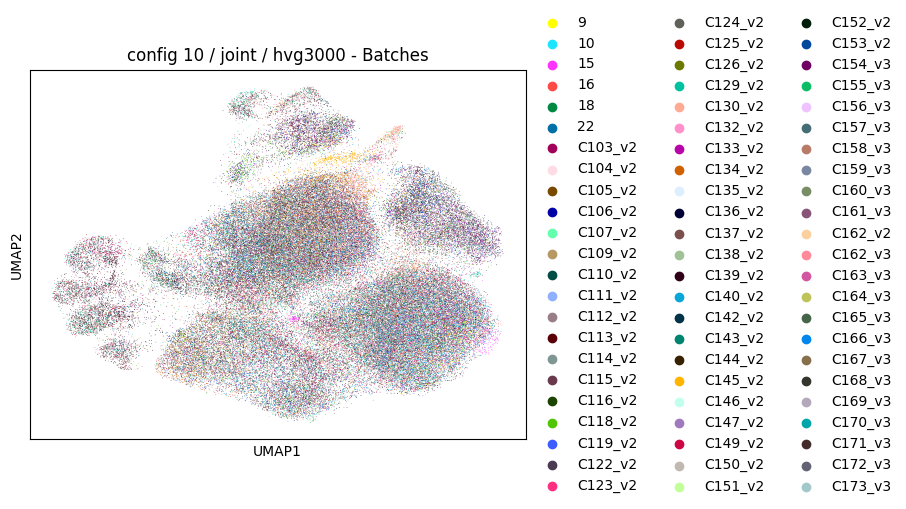

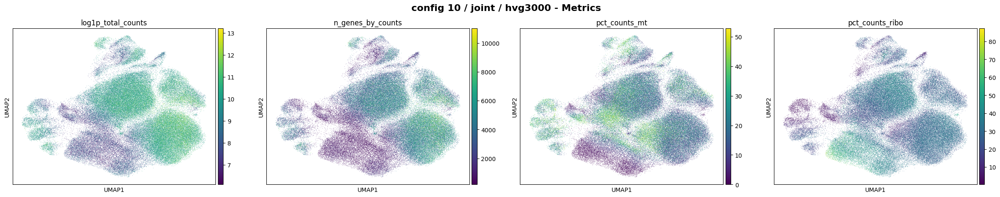

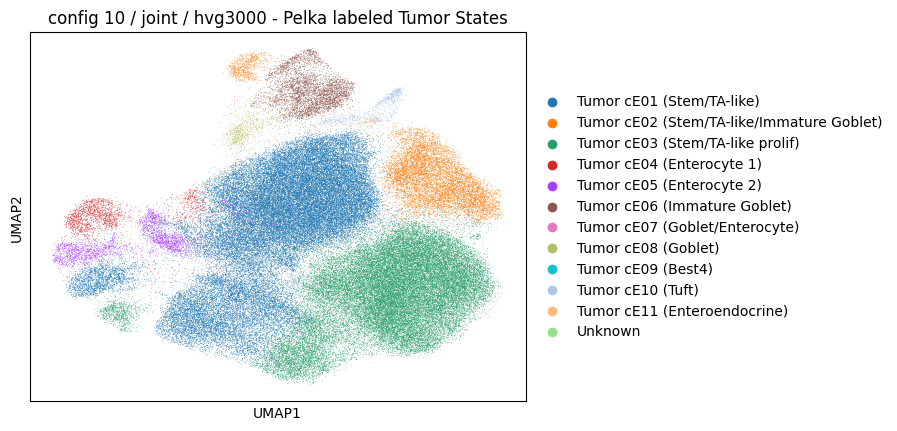

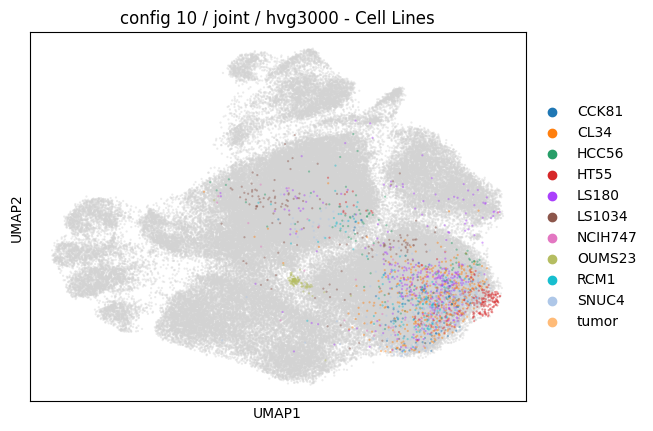

In [6]:
#top1
adata_10_joint = plot_umaps_sc(10, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg10000/config_50/joint/joint_scanvi/model.pt       
         already downloaded                                                                                        


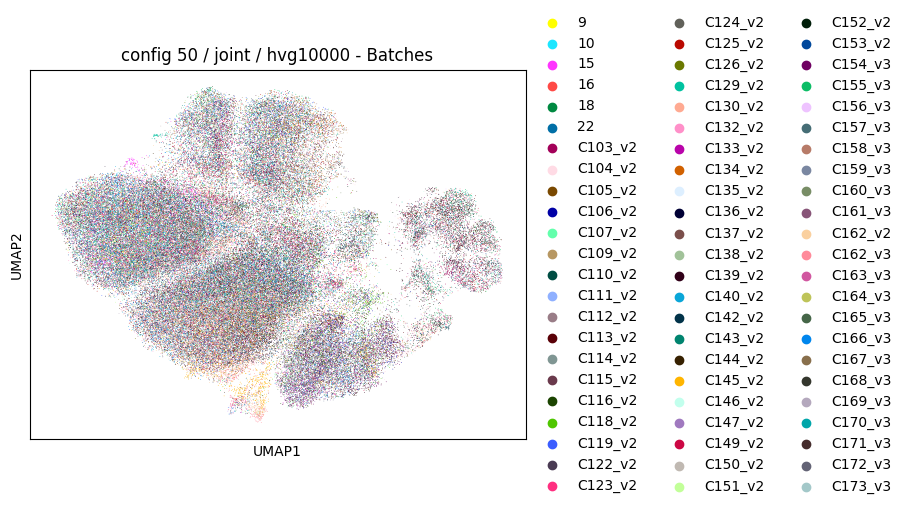

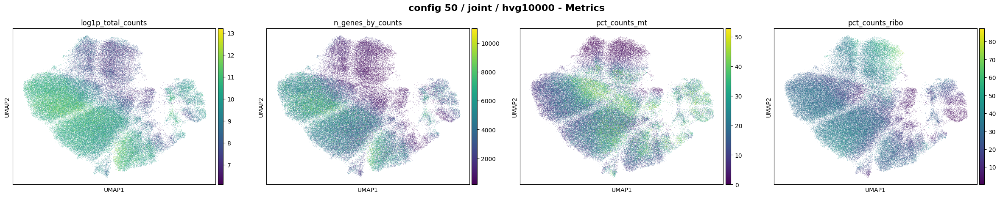

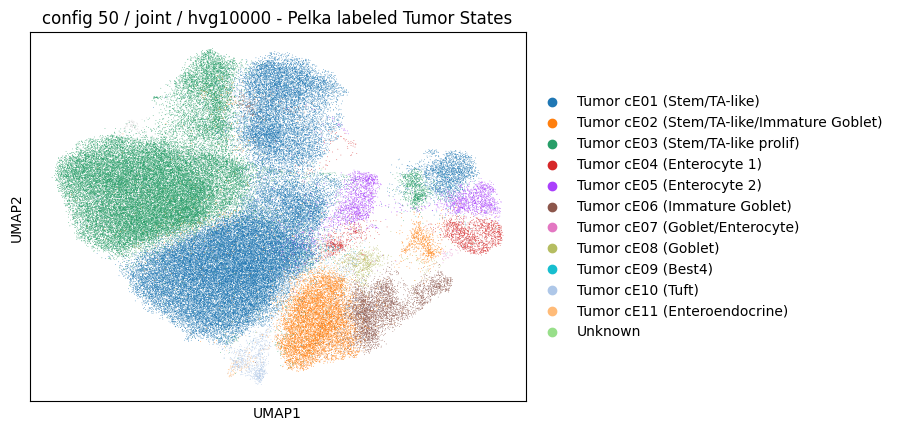

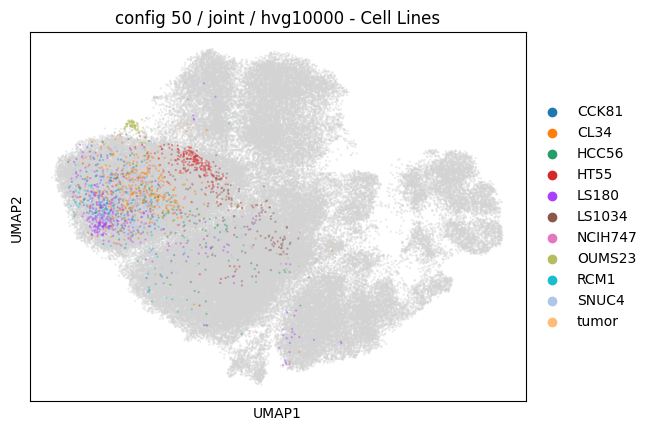

AnnData object with n_obs × n_vars = 110293 × 10000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [7]:
#top2
plot_umaps_sc(50, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_11/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


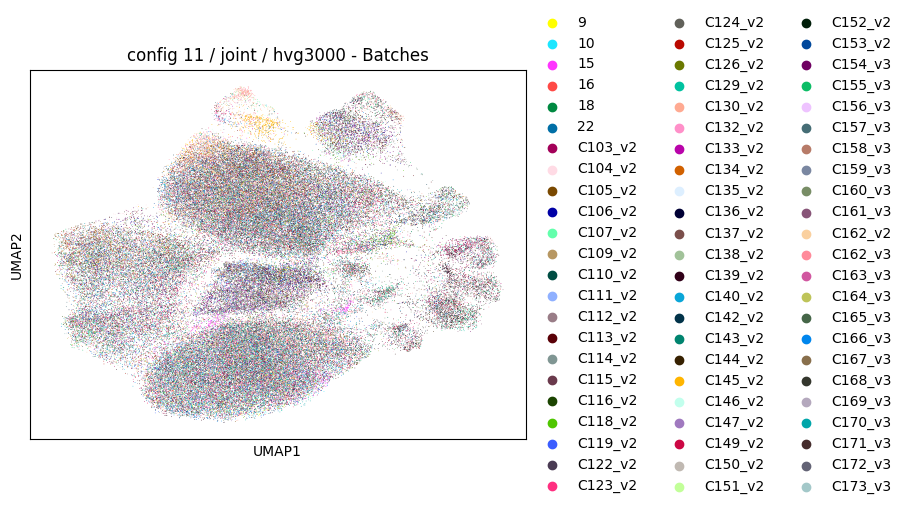

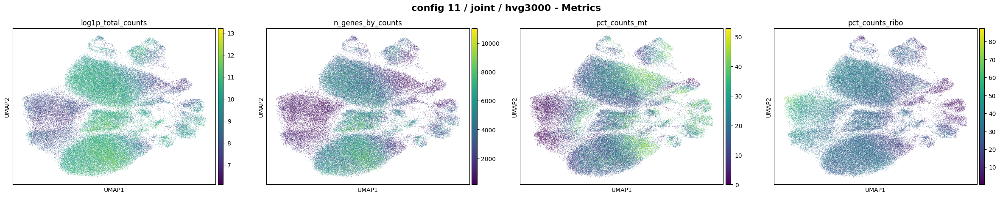

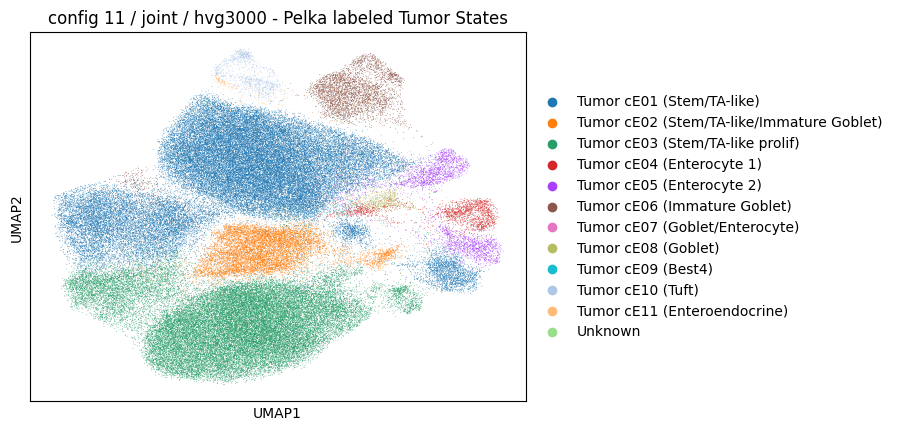

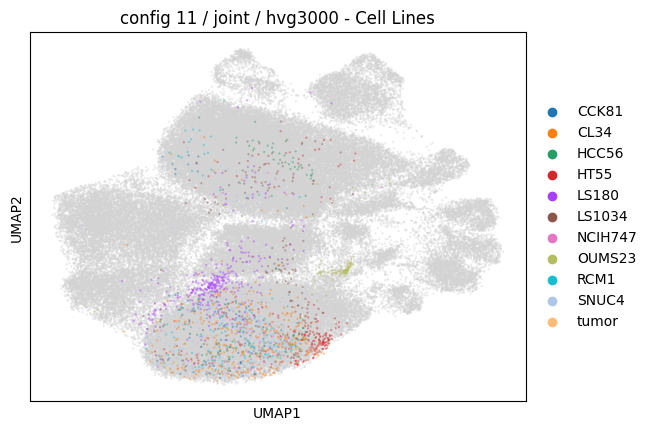

AnnData object with n_obs × n_vars = 110293 × 3000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [8]:
#top3
plot_umaps_sc(11, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg10000/config_47/scarches/query/model.pt already   
         downloaded                                                                                                


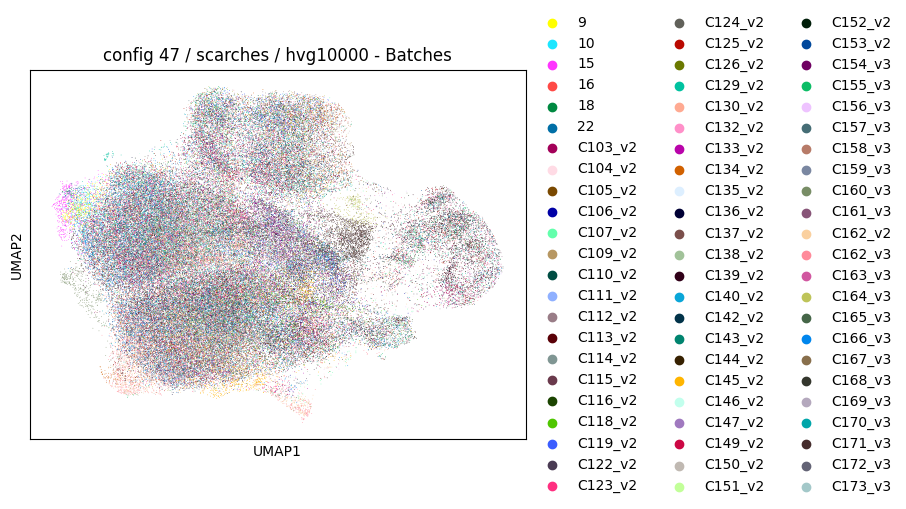

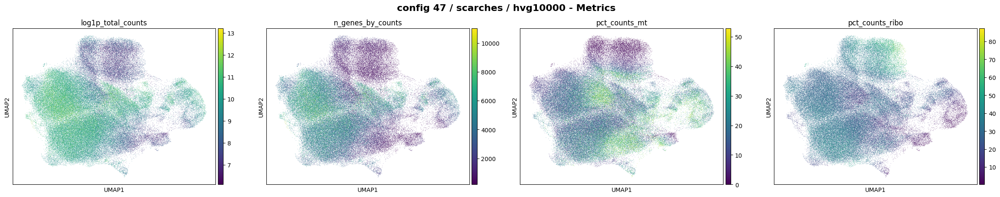

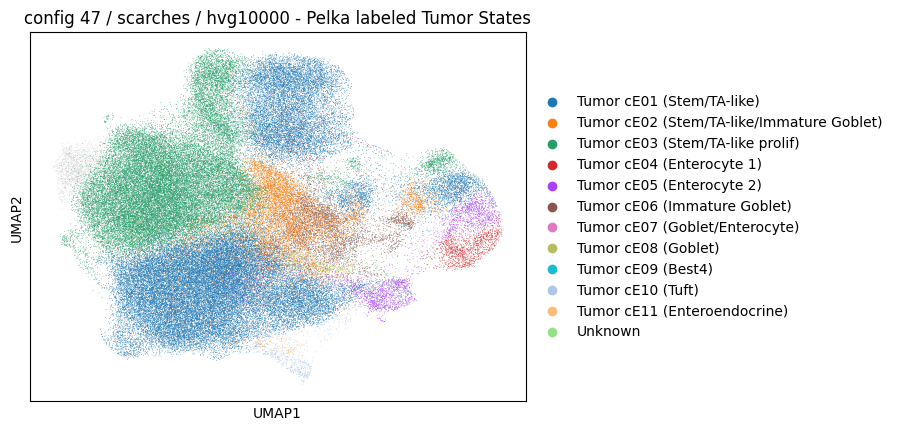

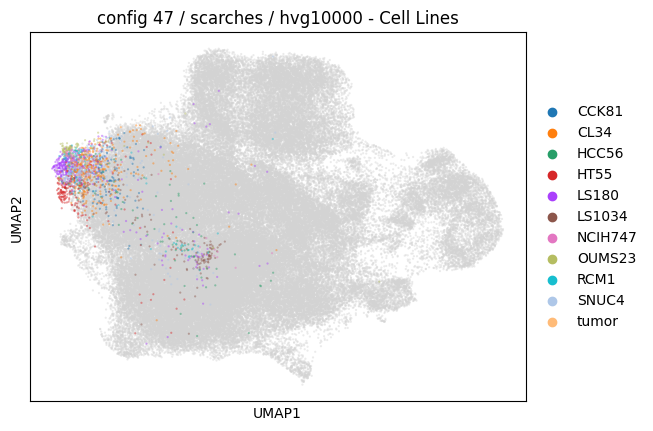

In [7]:
#top1
adata_47_scarches = plot_umaps_sc(47, "scarches")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg5000/config_23/scarches/query/model.pt already    
         downloaded                                                                                                


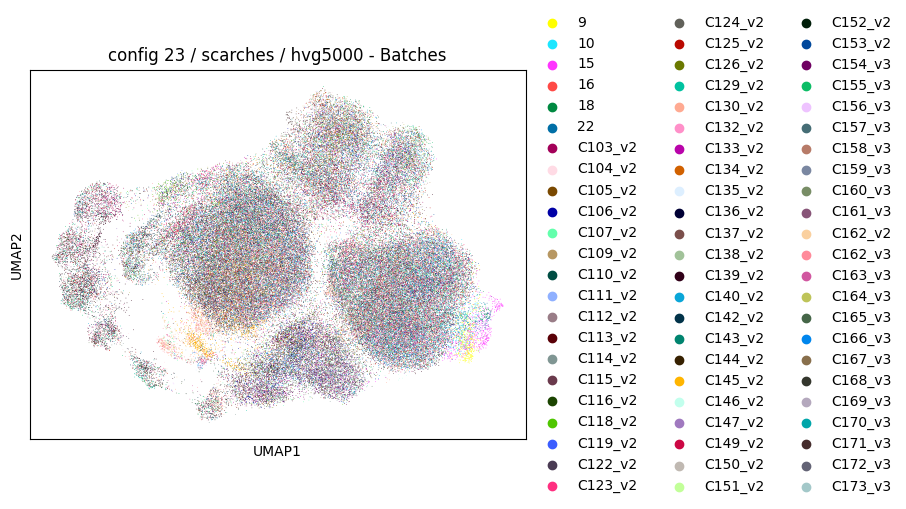

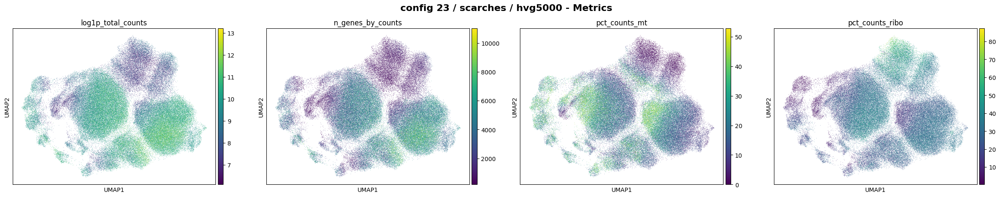

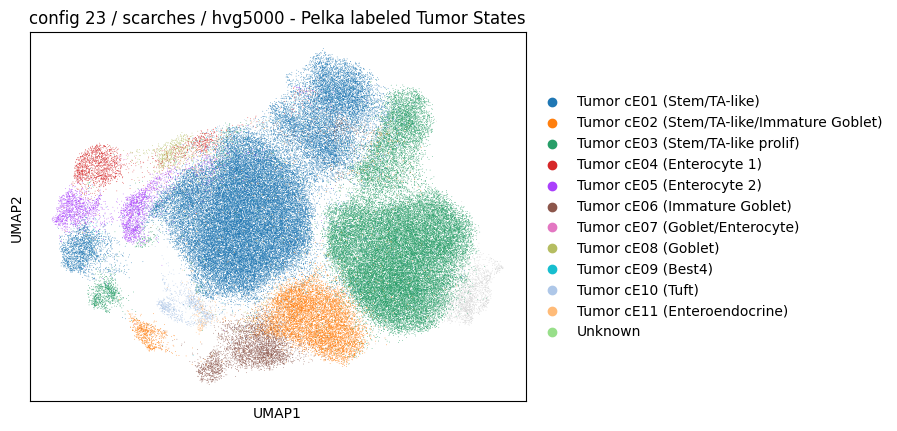

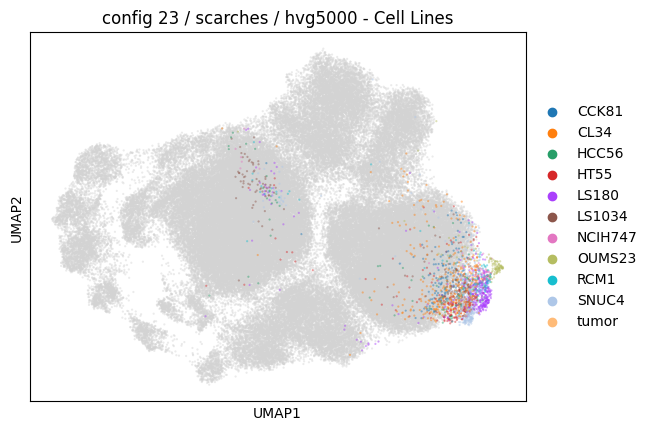

AnnData object with n_obs × n_vars = 110293 × 5000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [10]:
#top2
plot_umaps_sc(23, "scarches")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg5000/config_19/scarches/query/model.pt already    
         downloaded                                                                                                


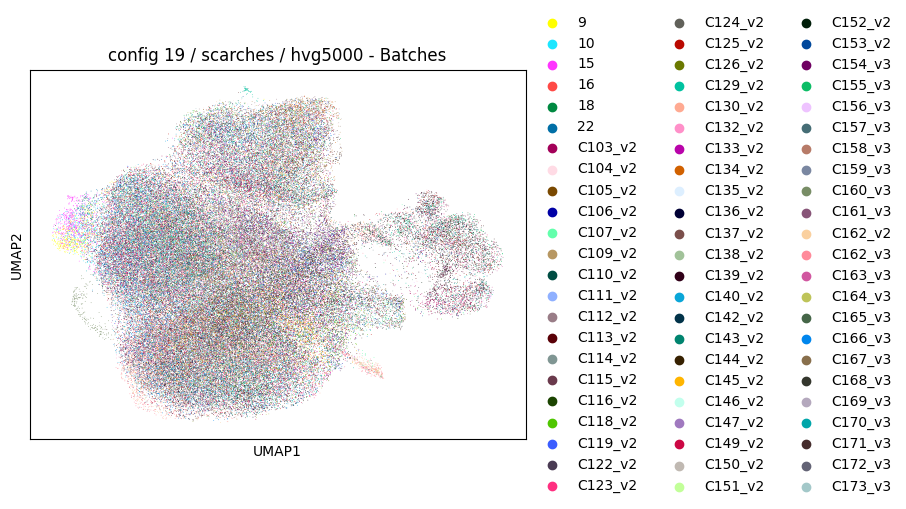

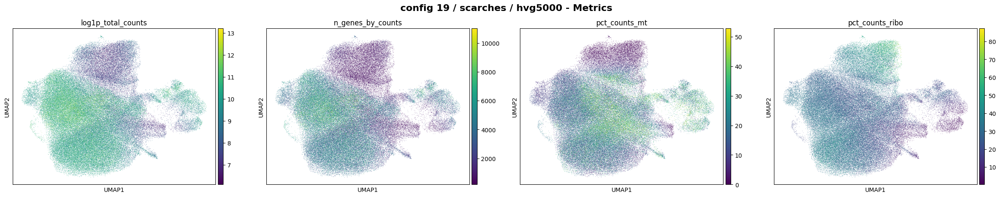

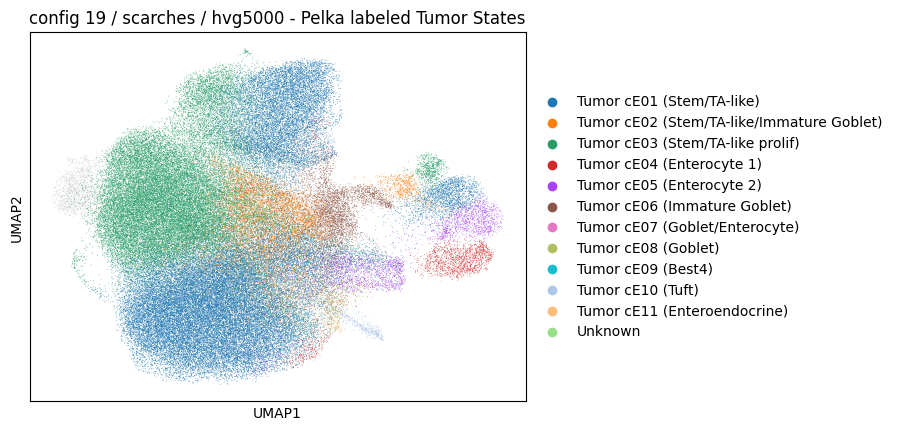

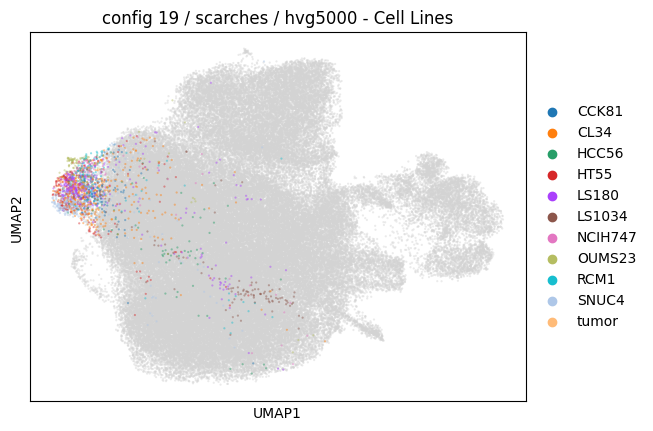

AnnData object with n_obs × n_vars = 110293 × 5000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [11]:
#top3
plot_umaps_sc(19, "scarches")

## UMAP best Models according to Dynamic K-Mixing

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg10000/config_47/joint/joint_scanvi/model.pt       
         already downloaded                                                                                        


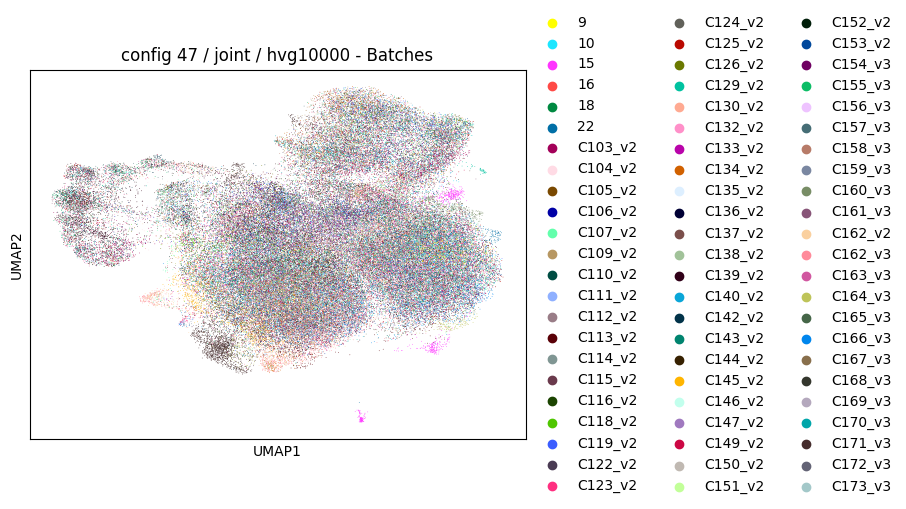

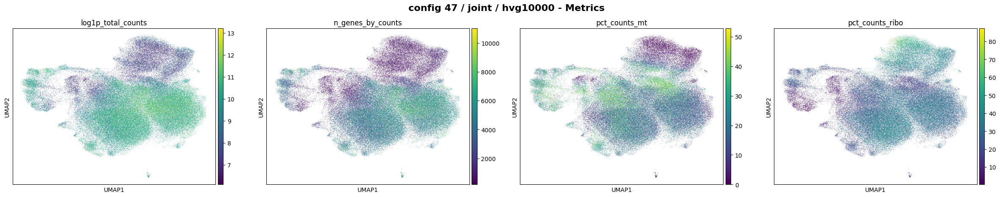

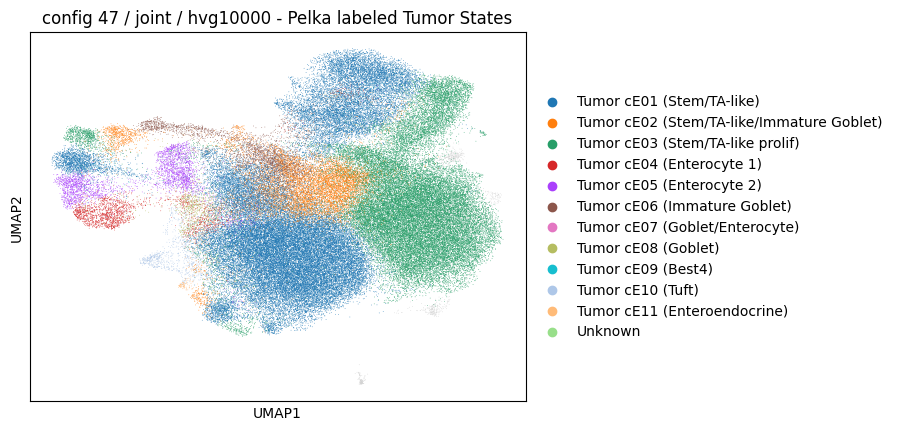

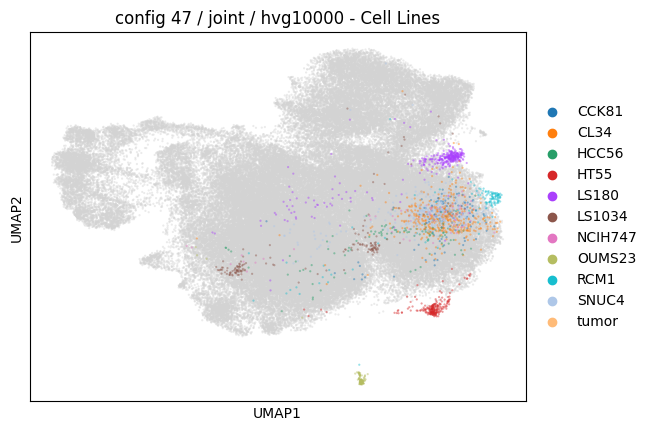

AnnData object with n_obs × n_vars = 110293 × 10000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [12]:
#top1
plot_umaps_sc(47, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


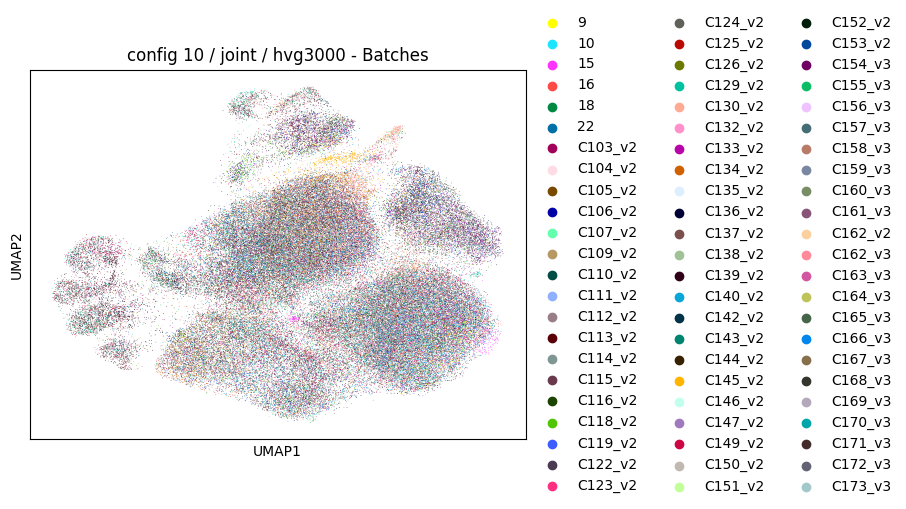

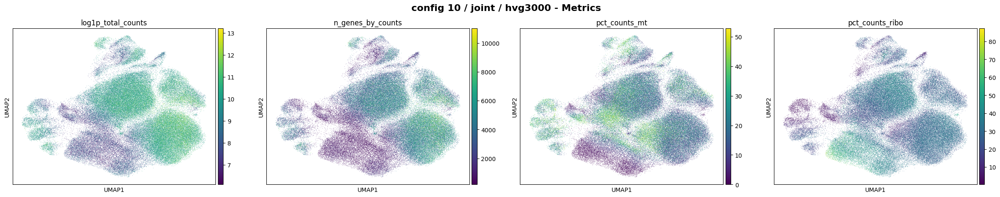

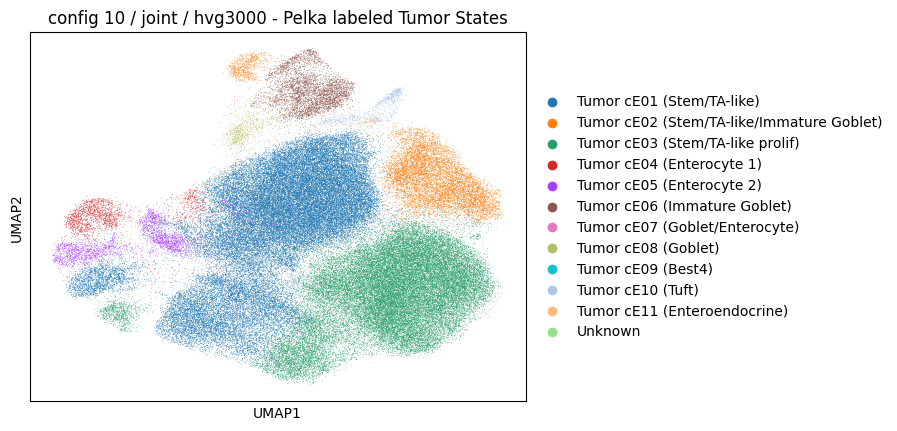

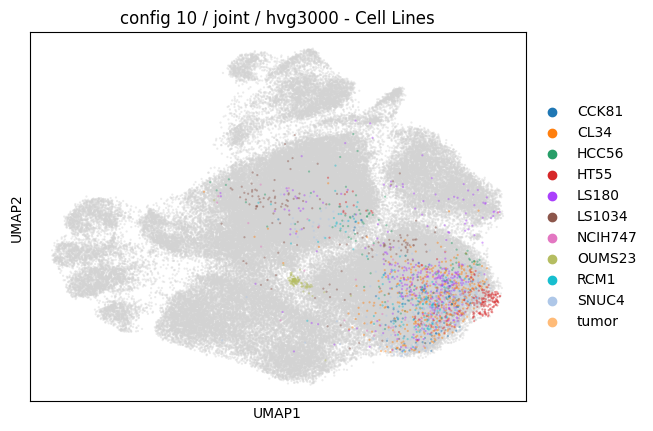

AnnData object with n_obs × n_vars = 110293 × 3000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [13]:
#top2
plot_umaps_sc(10, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_03/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


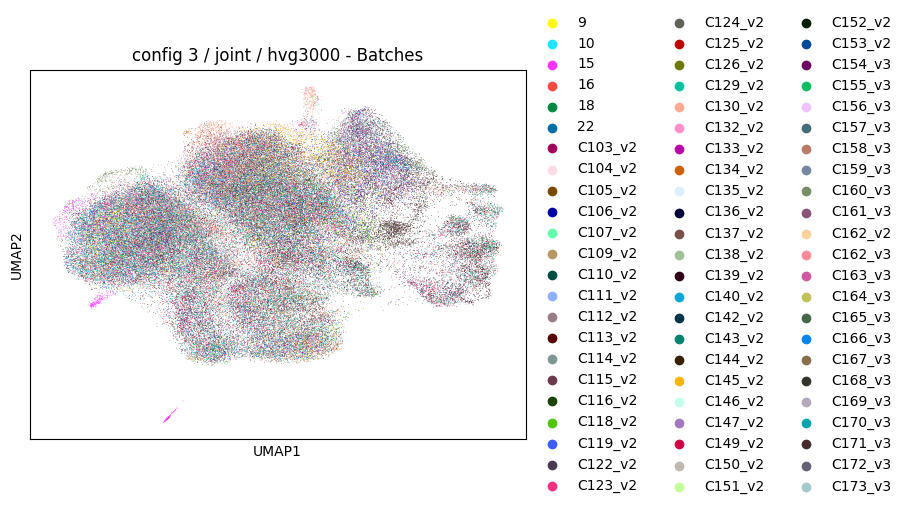

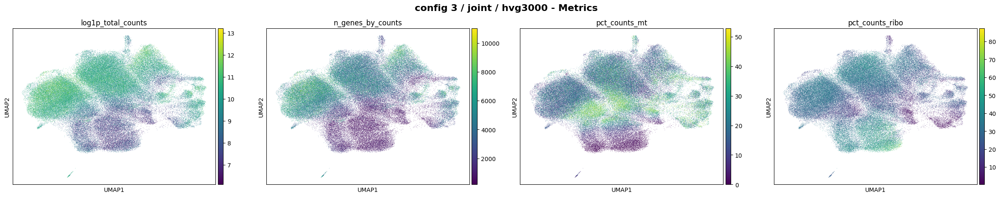

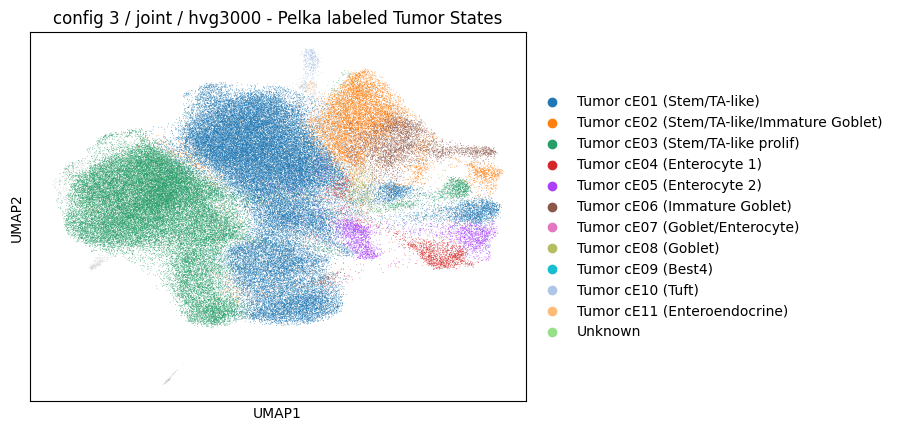

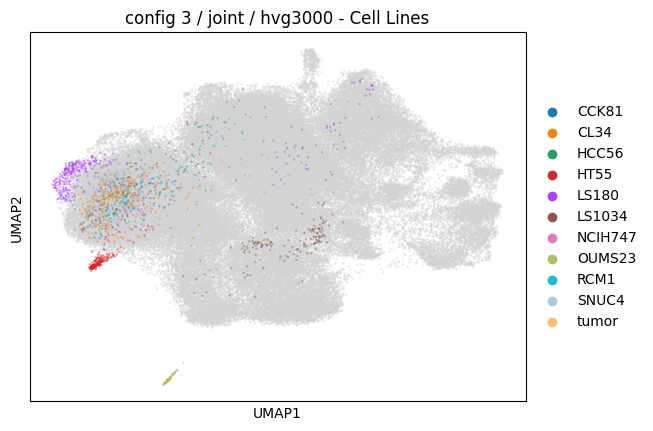

AnnData object with n_obs × n_vars = 110293 × 3000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [14]:
#top3
plot_umaps_sc(3, "joint")

In [ ]:
#top1
plot_umaps_sc(47, "scarches")

In [ ]:
#top2
plot_umaps_sc(23, "scarches")

In [ ]:
#top3
plot_umaps_sc(19, "scarches")

# Best scArches vs worst joint

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg5000/config_24/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


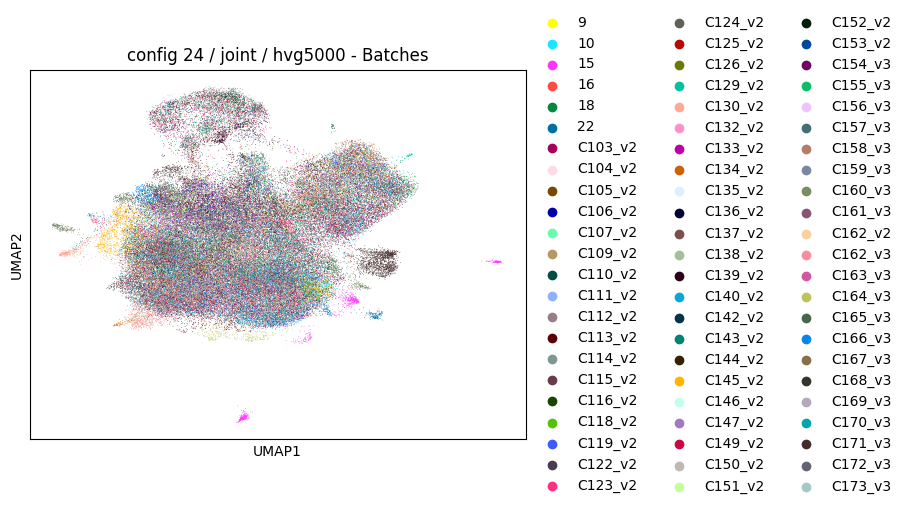

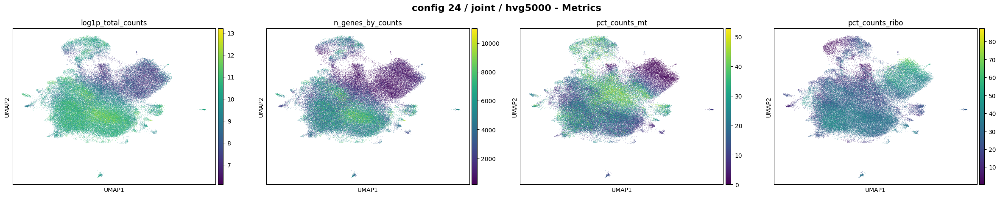

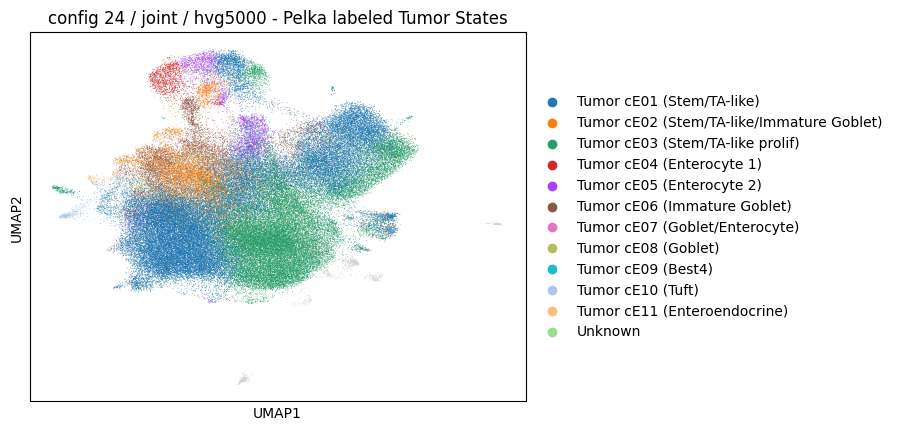

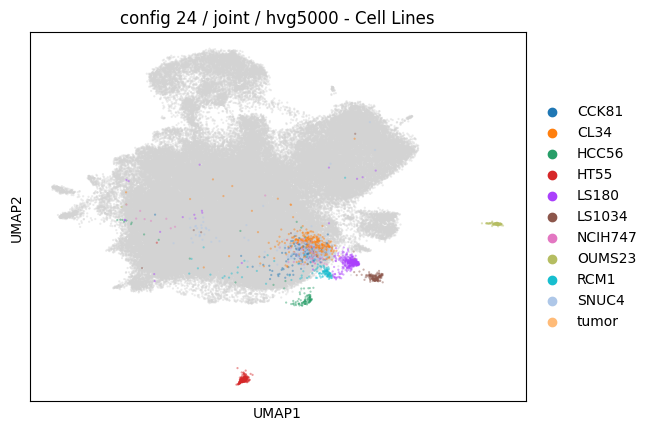

AnnData object with n_obs × n_vars = 110293 × 5000
    obs: 'cell_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset', 'label', 'donor_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'batch_colors', 'label_colors', 'cell_line_colors'
    obsm: 'X_latent', 'X_umap'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [8]:
plot_umaps_sc(24, "joint")

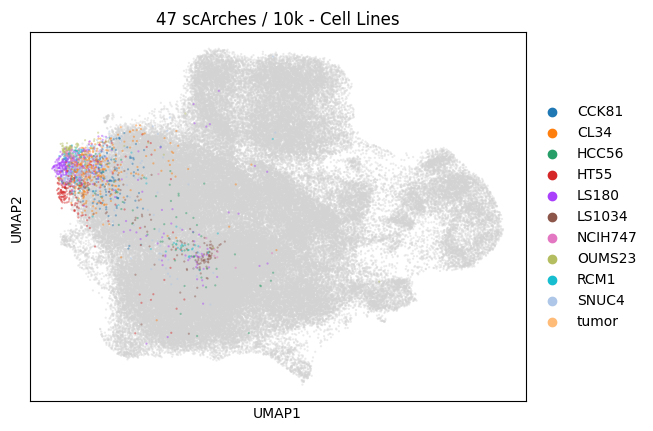

In [16]:
sc.pl.umap(
    adata_47_scarches,
    mask_obs=(adata_47_scarches.obs.dataset=="cell_line"),
    color=["cell_line"],
    na_in_legend=False,
    title=f"47 scArches / 10k - Cell Lines",
    size=10,
    alpha=0.45,
)

In [ ]:
#plot_umaps_sc(47, "scarches")

# Matplotlib Workflow 

Plotting `plot_umaps(config_id, approach, n_tumor=...)` using the `umap` package directly and drawing 1x4 matplotlib panels.

In [10]:
import umap

def plot_umaps(config_id, approach, seed=0):
    """Load a run by (config_id, approach) and plot its latent UMAP panels.

    Returns the figure; panels are also shown inline. UMAP runs on the full
    combined latent (~110k cells) - heavy, intended for a GPU machine.
    """
    adata = load_run_adata_with_latent(config_id, approach)
    latent = np.asarray(adata.obsm["X_latent"])
    combined = adata

    order = np.random.default_rng(seed).permutation(combined.n_obs)
    latent = latent[order]
    obs = combined.obs.iloc[order]
    is_cl_sel = (obs["dataset"] == "cell_line").to_numpy()

    emb = umap.UMAP(
        n_neighbors=15, min_dist=0.3, random_state=seed, n_jobs=-1,
    ).fit_transform(latent)

    line_colors = {
        line: plt.cm.tab20(i % 20)
        for i, line in enumerate(sorted(obs.loc[is_cl_sel, "cell_line"].unique()))
    }
    label_colors = {
        lab: plt.cm.tab20(i % 20)
        for i, lab in enumerate(sorted(obs.loc[~is_cl_sel, "label"].unique()))
    }
    batch_colors = {
        b: plt.cm.tab20(i % 20)
        for i, b in enumerate(sorted(obs.loc[~is_cl_sel, "batch"].astype(str).unique()))
    }

    fig, axes = plt.subplots(1, 4, figsize=(28, 7))
    for ax in axes:
        ax.scatter(emb[~is_cl_sel, 0], emb[~is_cl_sel, 1], s=1.5, c="lightgrey",
                   rasterized=True, alpha=0.5, linewidths=0)

    ax = axes[0]
    ax.scatter(emb[is_cl_sel, 0], emb[is_cl_sel, 1], s=6, c="tab:red",
               rasterized=True, linewidths=0)
    ax.set_title("tumor (grey) vs cell lines (red)")

    ax = axes[1]
    for line, color in line_colors.items():
        m = is_cl_sel & (obs["cell_line"].to_numpy() == line)
        ax.scatter(emb[m, 0], emb[m, 1], s=6, c=[color], label=line,
                   rasterized=True, linewidths=0)
    ax.set_title("cell-line identity")
    ax.legend(fontsize=7, markerscale=2, ncol=2, loc="upper right")

    ax = axes[2]
    for lab, color in label_colors.items():
        m = ~is_cl_sel & (obs["label"].to_numpy() == lab)
        ax.scatter(emb[m, 0], emb[m, 1], s=1.5, c=[color], label=lab,
                   rasterized=True, linewidths=0)
    ax.set_title("tumor Pelka labels")
    ax.legend(fontsize=6, markerscale=2, ncol=2, loc="upper right")

    ax = axes[3]
    for b, color in batch_colors.items():
        m = ~is_cl_sel & (obs["batch"].astype(str).to_numpy() == b)
        ax.scatter(emb[m, 0], emb[m, 1], s=1.5, c=[color], rasterized=True,
                   linewidths=0)
    ax.set_title(f"tumor batch ({len(batch_colors)})")

    fig.suptitle(f"config {config_id} / hvg{CONFIG_NUM_HVG[config_id]} / {approach}"
                 f" ({combined.n_obs} cells)")
    fig.tight_layout()
    plt.show()
    return fig

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg3000/config_10/joint/joint_scanvi/model.pt already
         downloaded                                                                                                


/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


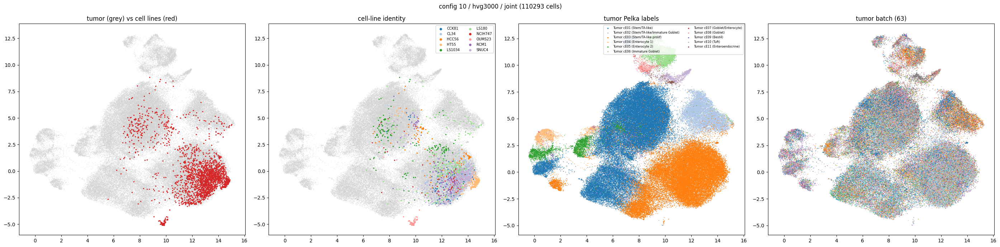

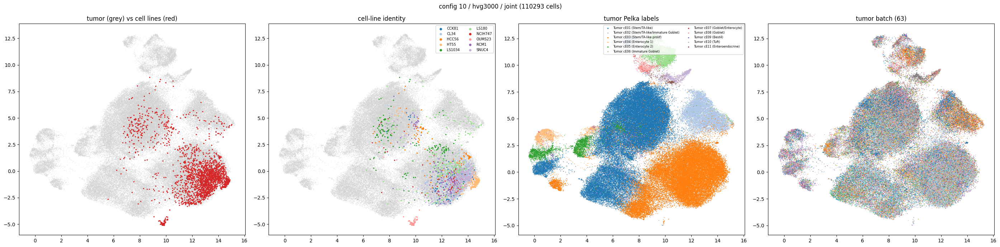

In [11]:
plot_umaps(10, "joint")

INFO     File /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg10000/config_47/scarches/query/model.pt already   
         downloaded                                                                                                


/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


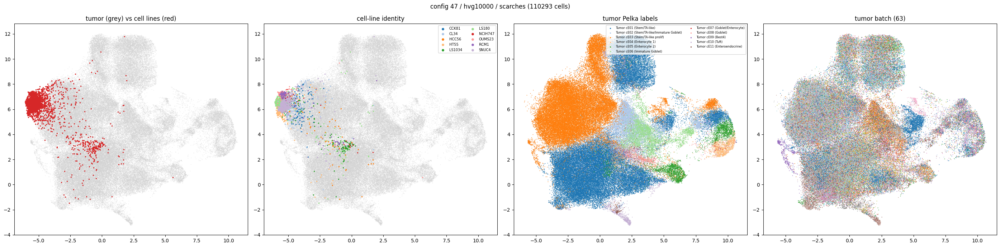

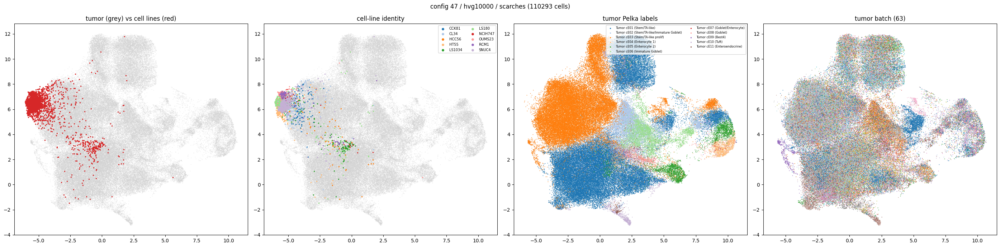

In [12]:
plot_umaps(47, "scarches")